# Fase 3 CRISP-DM — Preparación de Datos, Limpieza EXIF y Particiones sin Fuga

Verifica las transformaciones reproducibles aplicadas en `03_preparacion_datos/`:
1. Eliminación del 100 % de metadatos EXIF en fotos propias (privacidad — PI1) y reducción de peso (374 MB → ~17 MB).
2. Deduplicación binaria exacta y registro de exclusiones (`excluded_own_photos.csv`).
3. Segmentación individual de `Mixed Qualit_Fruits` (CIELAB + Otsu + Watershed).
4. Verificación estricta de cero fuga de grupos perceptuales (`dHash` + `source_group_id`) entre `train`, `val` y `test`.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import EXCLUDED_OWN_CSV, FRUITNET_SPLITS_CSV, OWN_ANNOTATIONS_CSV, DIR_FIGURAS

own_df = pd.read_csv(OWN_ANNOTATIONS_CSV)
excl_df = pd.read_csv(EXCLUDED_OWN_CSV)
splits_df = pd.read_csv(FRUITNET_SPLITS_CSV)

exif_count = sum(len(Image.open(PROJECT_ROOT / p).getexif()) > 0 for p in own_df["image_path"])
total_mb = own_df["file_bytes"].sum() / 1e6
print(f"Fotos propias limpias: {len(own_df)} | Peso total: {total_mb:.2f} MB | Con EXIF restante: {exif_count}")
assert exif_count == 0, "Quedaron metadatos EXIF en fotos propias"

print(f"\nRegistro de exclusiones/duplicados ({len(excl_df)} archivos):")
display(excl_df)

Fotos propias limpias: 307 | Peso total: 16.84 MB | Con EXIF restante: 0

Registro de exclusiones/duplicados (6 archivos):


,original_path,species,original_folder_label,original_sha256,reason
0,data/own_photos/limon/Buena/IMG-20261112-WA009...,limon,Buena,c8ef3b52c0624a108dee45ab2fb5e376add263a69adc83...,Duplicado binario exacto de data/own_photos/li...
1,data/own_photos/limon/Regular/IMG-20261112-WA0...,limon,Regular,e4b2f1a5f218e0329c61e2f3657cd0b7446e8f126f7612...,Duplicado binario exacto de data/own_photos/li...
2,data/own_photos/limon/Descartar/IMG-20261112-W...,limon,Descartar,8e9f4a4154a2ed17c09256edb224298a370cb942adad5b...,Descartada manualmente en revisión del equipo
3,data/own_photos/limon/Descartar/IMG-20261112-W...,limon,Descartar,c36544b7838732ec2bf5742d84eb4df8c1c91caee9f2eb...,Descartada manualmente en revisión del equipo
4,data/own_photos/limon/Descartar/IMG-20261112-W...,limon,Descartar,6b23a2cb81f629dca2120d62cda729ff6e8b68fb92d6d5...,Descartada manualmente en revisión del equipo
5,data/own_photos/limon/Descartar/IMG-20261112-W...,limon,Descartar,3c2719a28b5b56f5f1d72a9d80293a76cbef661197b026...,Descartada manualmente en revisión del equipo


In [2]:
# Verificación matemática de cero fuga de grupos entre train, val y test
tr_g = set(splits_df.loc[splits_df["split"].eq("train"), "leakage_group"])
va_g = set(splits_df.loc[splits_df["split"].eq("val"), "leakage_group"])
te_g = set(splits_df.loc[splits_df["split"].eq("test"), "leakage_group"])

assert not (tr_g & va_g), "Fuga detectada entre train y val"
assert not (tr_g & te_g), "Fuga detectada entre train y test"
assert not (va_g & te_g), "Fuga detectada entre val y test"

print(f"Grupos únicos totales: {splits_df['leakage_group'].nunique()} | Solapamiento entre splits: 0")
display(pd.crosstab(splits_df["split"], splits_df["quality"], margins=True))
display(pd.crosstab(splits_df["split"], splits_df["source"], margins=True))

Grupos únicos totales: 792 | Solapamiento entre splits: 0


quality,Buena,Mala,Regular,All
split,,,,
test,87,87,20,194
train,278,280,63,621
val,70,70,16,156
All,435,437,99,971


source,FruitNet_Kaggle,FruitNet_Mixed_Segmentada,Propia,All
split,,,,
test,116,17,61,194
train,371,53,197,621
val,93,14,49,156
All,580,84,307,971


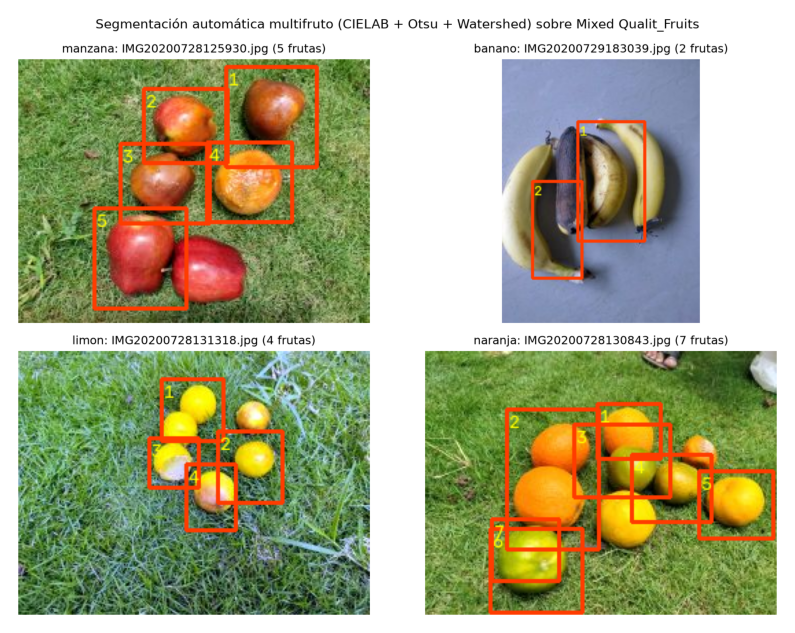

In [3]:
# Evidencia visual de la segmentación multifruto en Mixed Qualit_Fruits
seg_fig = DIR_FIGURAS / "07_segmentacion_mixed.png"
if seg_fig.is_file():
    plt.figure(figsize=(10, 8))
    plt.imshow(Image.open(seg_fig))
    plt.axis("off")
    plt.show()

In [4]:
# Verificación de integridad unificada (calidad + tamaño) en 307/307 fotos propias
from src.config import ANNOTATIONS_DIR
from src.size_estimation import classify_size_category

size_ref_df = pd.read_csv(ANNOTATIONS_DIR / "size_references.csv")
assert len(own_df) == 307 and len(size_ref_df) == 307, "Se esperan 307 filas en own_annotations y size_references"
assert own_df["reference_normalized_diameter"].notna().all()
assert own_df["size_category"].notna().all()
assert all(
    row["reference_size_category"] == classify_size_category(float(row["reference_normalized_diameter"]))
    for _, row in size_ref_df.iterrows()
)
print("Cobertura unificada calidad + tamaño: 307/307 fotos propias verificadas.")
display(pd.crosstab(own_df["species"], own_df["size_category"], margins=True))

Cobertura unificada calidad + tamaño: 307/307 fotos propias verificadas.


size_category,Grande,Mediano,Pequeño,All
species,,,,
banano,30,2,0,32
limon,0,43,2,45
mango,0,18,40,58
manzana,16,4,9,29
naranja,0,17,68,85
tomate_arbol,0,1,57,58
All,46,85,176,307
